In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'jax', 'jaxlib', 'flax', 'optax', 'orbax-checkpoint', 'tensorflow', 'protobuf', 'ml-dtypes']
imports = {'pillow': 'PIL', 'orbax-checkpoint': 'orbax', 'protobuf': 'google.protobuf', 'ml-dtypes': 'ml_dtypes'}
pinned = {'jax': ('0.12.0.1', 'jax==0.12.0.1', 'jax[cuda12]==0.12.0.1', 'exact'), 'jaxlib': ('0.12.0.1', 'jaxlib==0.12.0.1', 'jaxlib==0.12.0.1', 'exact'), 'flax': ('0.12.12', 'flax==0.12.12', 'flax==0.12.12', 'exact'), 'optax': ('0.2.8', 'optax==0.2.8', 'optax==0.2.8', 'exact'), 'orbax-checkpoint': ('0.12.0', 'orbax-checkpoint==0.12.0', 'orbax-checkpoint==0.12.0', 'exact')}
fallbacks = {'tensorflow': 'tensorflow==2.21.0', 'protobuf': 'protobuf==7.34.1', 'ml-dtypes': 'ml-dtypes==0.5.4'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'jax' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'jax' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, _, _, match) in pinned.items():
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "8a5255b0fce49fc730baae6ea6ecc601d45bb16b"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/8a5255b0fce49fc730baae6ea6ecc601d45bb16b/d2l"
for name in ('__init__.py', 'jax.py', 'nnx_resnet.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Fully Convolutional Networks

As discussed in that section,
semantic segmentation
classifies images in pixel level.
A fully convolutional network (FCN)
uses a convolutional neural network to
transform image pixels to pixel classes [@Long.Shelhamer.Darrell.2015].
Unlike the CNNs that we encountered earlier
for image classification 
or object detection,
a fully convolutional network
transforms 
the height and width of intermediate feature maps
back to those of the input image:
this is achieved by
the transposed convolutional layer
introduced in that section.
As a result,
the classification output
and the input image 
have a one-to-one correspondence 
in pixel level:
the channel dimension at any output pixel 
holds the classification results
for the input pixel at the same spatial position.

In [ ]:
import math
import numpy as np
import jax
from jax import numpy as jnp
from flax import nnx
import optax
from d2l import jax as d2l

In [ ]:
from PIL import Image
from d2l.nnx_resnet import ResNet50

## The Model

Here we describe the basic design of the fully convolutional network model. 
As shown in the figure,
this model first uses a CNN to extract image features,
then transforms the number of channels into
the number of classes
via a $1\times 1$ convolutional layer,
and finally transforms the height and width of
the feature maps
to those
of the input image via
the transposed convolution introduced in that section. 
As a result,
the model output has the same height and width as the input image,
where the output channel contains the predicted classes
for the input pixel at the same spatial position.


![Fully convolutional network.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/fcn.svg)

Below, we use a ResNet model pretrained on the ImageNet dataset to extract image features
and denote the model instance as `pretrained_net`.
The last few layers of this model
include a global average pooling layer
and a fully connected layer:
they are not needed
in the fully convolutional network.

In [2]:
pretrained_net = ResNet50.from_pretrained()
dummy = jnp.ones((1, 320, 480, 3))
print('Feature extractor output shape:',
      pretrained_net.feature_map(dummy).shape)

Feature extractor output shape: (1, 10, 15, 2048)


Next, we create the fully convolutional network instance `net`.
It copies all the pretrained convolutional layers in the ResNet
except for the final global average pooling layer
and the fully connected layer that are closest
to the output.

In [3]:
# `feature_map` omits the global average pooling and classification head.

Given an input with height and width of 320 and 480 respectively,
the forward propagation of `net`
reduces the input height and width to 1/32 of the original, namely 10 and 15.

In [4]:
X = jnp.ones((1, 320, 480, 3))
pretrained_net.feature_map(X).shape

(1, 10, 15, 2048)

Next, we use a $1\times 1$ convolutional layer to transform the number of output channels into the number of classes (21) of the Pascal VOC2012 dataset.
Finally, we need to increase the height and width of the feature maps by 32 times to change them back to the height and width of the input image. 
Recall how to calculate 
the output shape of a convolutional layer in that section. 
Since $(320-64+16\times2+32)/32=10$ and $(480-64+16\times2+32)/32=15$, we construct a transposed convolutional layer with stride of $32$, 
setting
the height and width of the kernel
to $64$, the padding to $16$.
In general,
we can see that
for stride $s$,
padding $s/2$ (assuming $s/2$ is an integer),
and the height and width of the kernel $2s$, 
the transposed convolution will increase
the height and width of the input by $s$ times.

In [5]:
num_classes = 21

class FCN(nnx.Module):
    """Fully Convolutional Network for semantic segmentation."""
    def __init__(self, backbone, num_classes, *, rngs):
        self.backbone = backbone
        self.classifier = nnx.Conv(2048, num_classes, (1, 1), rngs=rngs)
        self.upsample = nnx.ConvTranspose(
            num_classes, num_classes, (64, 64), strides=32, padding='SAME',
            use_bias=False, rngs=rngs)

    def __call__(self, X):
        X = self.backbone.feature_map(X)
        return self.upsample(self.classifier(X))

net = FCN(pretrained_net, num_classes, rngs=nnx.Rngs(0))
print('FCN output shape:',
      net(jnp.ones((1, 320, 480, 3))).shape)

FCN output shape: (1, 320, 480, 21)


## Initializing Transposed Convolutional Layers


We already know that
transposed convolutional layers can increase
the height and width of
feature maps.
In image processing, we may need to scale up
an image, i.e., *upsampling*.
*Bilinear interpolation*
is one of the commonly used upsampling techniques.
It is also often used for initializing transposed convolutional layers.

To explain bilinear interpolation,
say that 
given an input image
we want to 
calculate each pixel 
of the upsampled output image.
In order to calculate the pixel of the output image
at coordinate $(x, y)$, 
first map $(x, y)$ to coordinate $(x', y')$ on the input image, for example, according to the ratio of the input size to the output size. 
Note that the mapped $x'$ and $y'$ are real numbers. 
Then, find the four pixels closest to coordinate
$(x', y')$ on the input image. 
Finally, the pixel of the output image at coordinate $(x, y)$ is calculated based on these four closest pixels
on the input image and their relative distance from $(x', y')$. 

Upsampling of bilinear interpolation
can be implemented by the transposed convolutional layer 
with the kernel constructed by the following `bilinear_kernel` function. 
Due to space limitations, we only provide the implementation of the `bilinear_kernel` function below
without discussions on its algorithm design.

In [6]:
def bilinear_kernel(in_channels, out_channels, kernel_size):
    factor = (kernel_size + 1) // 2
    if kernel_size % 2 == 1:
        center = factor - 1
    else:
        center = factor - 0.5
    og = (np.arange(kernel_size).reshape(-1, 1),
          np.arange(kernel_size).reshape(1, -1))
    filt = (1 - np.abs(og[0] - center) / factor) * \
           (1 - np.abs(og[1] - center) / factor)
    # Flax uses HWIO format for ConvTranspose kernels
    weight = np.zeros((kernel_size, kernel_size, in_channels, out_channels))
    for i in range(min(in_channels, out_channels)):
        weight[:, :, i, i] = filt
    return jnp.array(weight)

Let's experiment with upsampling of bilinear interpolation 
that is implemented by a transposed convolutional layer. 
We construct a transposed convolutional layer that 
doubles the height and weight,
and initialize its kernel with the `bilinear_kernel` function.

In [7]:
class BilinearConvTranspose(nnx.Module):
    """A transposed conv layer initialized with bilinear interpolation."""
    def __init__(self, channels, kernel_size, strides, *, rngs):
        self.layer = nnx.ConvTranspose(
            channels, channels, (kernel_size, kernel_size), strides=strides,
            padding='SAME', use_bias=False, rngs=rngs)
        self.layer.kernel[...] = bilinear_kernel(
            channels, channels, kernel_size)

    def __call__(self, X):
        return self.layer(X)

conv_trans = BilinearConvTranspose(3, 4, (2, 2), rngs=nnx.Rngs(0))

Read the image `X` and assign the upsampling output to `Y`. In order to print the image, we need to adjust the position of the channel dimension.

In [8]:
img = np.array(Image.open('../img/catdog.jpg')).astype(np.float32) / 255
X = jnp.expand_dims(jnp.array(img), axis=0)  # NHWC
Y = conv_trans(X)
out_img = np.array(Y[0])

As we can see, the transposed convolutional layer increases both the height and width of the image by a factor of two.
Except for the different scales in coordinates,
the image scaled up by bilinear interpolation and the original image printed in that section look the same.

input image shape: (561, 728, 3)
output image shape: (1122, 1456, 3)


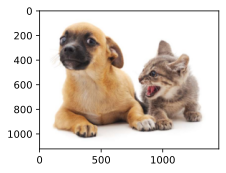

In [9]:
d2l.set_figsize()
print('input image shape:', img.shape)
d2l.plt.imshow(img);
print('output image shape:', out_img.shape)
d2l.plt.imshow(out_img);

In a fully convolutional network, we initialize the transposed convolutional layer with upsampling of bilinear interpolation. For the $1\times 1$ convolutional layer, we use Xavier initialization.

In [10]:
# Initialize the FCN with bilinear weights for the transposed conv layer
# and Xavier initialization for the 1x1 conv layer
W = bilinear_kernel(num_classes, num_classes, 64)
net.upsample.kernel[...] = W

## Reading the Dataset

We read
the semantic segmentation dataset
as introduced in that section. 
The output image shape of random cropping is
specified as $320\times 480$: both the height and width are divisible by $32$.

In [11]:
# The NNX ResNet-50 is deeper than the ResNet-18 used in the PyTorch tab, so
# use a smaller minibatch while keeping the same crops and number of epochs.
batch_size, crop_size = 4, (320, 480)
train_iter, test_iter = d2l.load_data_voc(batch_size, crop_size)

read 1114 examples


read 1078 examples


## Training


Now we can train our constructed
fully convolutional network. 
The loss function and accuracy calculation here
are not essentially different from those in image classification of earlier chapters. 
Because we use the output channel of the
transposed convolutional layer to
predict the class for each pixel,
the channel dimension is specified in the loss calculation.
In addition, the accuracy is calculated
based on correctness
of the predicted class for all the pixels.

In [12]:
num_epochs, lr, wd = 5, 0.001, 1e-3
def parameter_labels(params):
    return jax.tree_util.tree_map_with_path(
        lambda path, _: ('head' if any(
            getattr(p, 'key', None) in ('classifier', 'upsample')
            for p in path) else 'backbone'), params)

optimizer = nnx.Optimizer(
    net, optax.multi_transform(
        {'head': optax.chain(optax.add_decayed_weights(wd),
                             optax.sgd(lr * 10)),
         'backbone': optax.chain(optax.add_decayed_weights(wd),
                                 optax.sgd(lr))},
        parameter_labels),
    wrt=nnx.Param)
eval_net = nnx.view(net, use_running_average=True, raise_if_not_found=False)

@nnx.jit
def train_step(model, optimizer, X, Y):
    def loss_fn(model):
        logits = model(X)
        loss = optax.softmax_cross_entropy_with_integer_labels(logits, Y)
        return loss.mean(), logits
    (loss, logits), grads = nnx.value_and_grad(loss_fn, has_aux=True)(model)
    optimizer.update(model, grads)
    correct = (jnp.argmax(logits, axis=-1) == Y).sum()
    return loss, correct

@nnx.jit
def eval_step(model, X, Y):
    logits = model(X)
    losses = optax.softmax_cross_entropy_with_integer_labels(logits, Y)
    correct = (jnp.argmax(logits, axis=-1) == Y).sum()
    return losses.sum(), correct

for epoch in range(num_epochs):
    loss_terms, correct_terms, num_pixels = [], [], 0
    for X, Y in train_iter:
        X = jnp.transpose(jnp.array(X), (0, 2, 3, 1))
        Y = jnp.array(Y)
        loss, correct = train_step(net, optimizer, X, Y)
        loss_terms.append(loss * Y.size)
        correct_terms.append(correct)
        num_pixels += Y.size
    val_loss_terms, val_correct_terms, val_pixels = [], [], 0
    for X, Y in test_iter:
        X = jnp.transpose(jnp.array(X), (0, 2, 3, 1))
        Y = jnp.array(Y)
        val_loss, val_correct = eval_step(eval_net, X, Y)
        val_loss_terms.append(val_loss)
        val_correct_terms.append(val_correct)
        val_pixels += Y.size
    loss_sum = float(jnp.stack(loss_terms).sum())
    correct = int(jnp.stack(correct_terms).sum())
    val_loss_sum = float(jnp.stack(val_loss_terms).sum())
    val_correct = int(jnp.stack(val_correct_terms).sum())
    print(f'epoch {epoch + 1}, loss {loss_sum / num_pixels:.3f}, '
          f'pixel acc {correct / num_pixels:.3f}, '
          f'val loss {val_loss_sum / val_pixels:.3f}, '
          f'val pixel acc {val_correct / val_pixels:.3f}')

epoch 1, loss 1.602, pixel acc 0.708, val loss 1.178, val pixel acc 0.733


epoch 2, loss 1.121, pixel acc 0.739, val loss 1.046, val pixel acc 0.751


epoch 3, loss 1.009, pixel acc 0.759, val loss 0.958, val pixel acc 0.767


epoch 4, loss 0.919, pixel acc 0.777, val loss 0.879, val pixel acc 0.781


epoch 5, loss 0.849, pixel acc 0.791, val loss 0.821, val pixel acc 0.793


## Prediction


When predicting, we need to standardize the input image
in each channel and transform the image into the four-dimensional input format required by the CNN.

In [13]:
def predict(img):
    rgb_mean = np.array([0.485, 0.456, 0.406])
    rgb_std = np.array([0.229, 0.224, 0.225])
    X = (img.astype(np.float32) / 255 - rgb_mean) / rgb_std
    X = jnp.expand_dims(jnp.array(X), axis=0)  # NHWC
    pred = nnx.view(net, use_running_average=True,
                    raise_if_not_found=False)(X)
    return jnp.argmax(pred, axis=-1).reshape(pred.shape[1], pred.shape[2])

To visualize the predicted class of each pixel, we map the predicted class back to its label color in the dataset.

In [14]:
def label2image(pred):
    colormap = jnp.array(d2l.VOC_COLORMAP, dtype=jnp.uint8)
    X = pred.astype(jnp.int32)
    return colormap[X, :]

Images in the test dataset vary in size and shape.
Since the model uses a transposed convolutional layer with stride of 32,
when the height or width of an input image is indivisible by 32,
the output height or width of the
transposed convolutional layer will deviate from the shape of the input image.
In order to address this issue,
we can crop multiple rectangular areas with height and width that are integer multiples of 32 in the image,
and perform forward propagation
on the pixels in these areas separately.
Note that
the union of these rectangular areas needs to completely cover the input image.
When a pixel is covered by multiple rectangular areas,
the average of the transposed convolution outputs
in separate areas for this same pixel
can be input to
the softmax operation
to predict the class.


For simplicity, we only read a few larger test images,
and crop a $320\times480$ area for prediction starting from the upper-left corner of an image.
For these test images, we
print their cropped areas,
prediction results,
and ground-truth row by row.

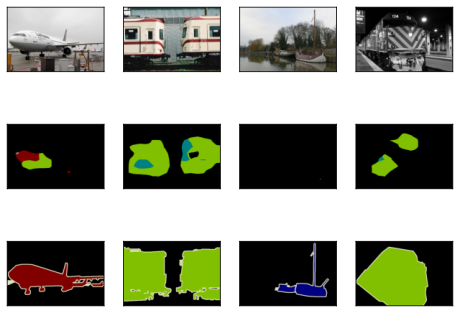

In [15]:
voc_dir = d2l.download_extract('voc2012', 'VOCdevkit/VOC2012')
test_images, test_labels = d2l.read_voc_images(voc_dir, False)
n, imgs = 4, []
for i in range(n):
    # Crop HWC arrays: top=0, left=0, height=320, width=480
    X = test_images[i][:320, :480, :]
    pred = label2image(predict(X))
    label_crop = test_labels[i][:320, :480, :]
    imgs += [X, np.array(pred), label_crop]
d2l.show_images(imgs[::3] + imgs[1::3] + imgs[2::3], 3, n, scale=2);

## Summary

* The fully convolutional network first uses a CNN to extract image features, then transforms the number of channels into the number of classes via a $1\times 1$ convolutional layer, and finally transforms the height and width of the feature maps to those of the input image via the transposed convolution.
* In a fully convolutional network, we can use upsampling of bilinear interpolation to initialize the transposed convolutional layer.


## Exercises

1. If we use Xavier initialization for the transposed convolutional layer in the experiment, how does the result change?
1. The text uses `bilinear_kernel` without deriving it. Work it out for `bilinear_kernel(1, 1, 4)`, the kernel of the layer `conv_trans` with stride 2 and padding 1.
    1. Show that the $4\times 4$ kernel is the outer product of a vector with itself, and give the vector.
    1. In one dimension, compute the six outputs of this transposed convolution for the input $(a, b, c)$. Show that the four interior outputs are the linear interpolations of the input at $1/4$ and $3/4$ of the way between neighboring input pixels, and find the factor by which the first and the last output differ from the neighboring input pixel.
    1. Predict the ratio between the upper-left pixel of the two-dimensional output and the upper-left pixel of the input, and check it for each of the three color channels by applying `conv_trans` to the cat-and-dog image of this section.
1. Can you further improve the accuracy of the model by tuning the hyperparameters?
1. Predict the classes of all pixels in test images.
1. Pixel accuracy is dominated by the background class. For the trained network, compute the intersection over union (IoU) of every class on the test crops of `test_iter`: the number of pixels that are both predicted and labeled as class $c$, divided by the number of pixels that are predicted or labeled as $c$, with both counts accumulated over the whole test set. Report the mean IoU over the 21 classes next to the test pixel accuracy, list the five classes with the lowest IoU, and describe what these classes have in common.
1. The original fully convolutional network paper also uses outputs of some intermediate CNN layers [@Long.Shelhamer.Darrell.2015]. Try to implement this idea.

[Discussions](https://d2l.discourse.group/t/1582)